In [17]:
import math
from collections import Counter
from pathlib import Path

def calculate_entropy(file_path):
    data = Path(file_path).read_bytes()

    if len(data) == 0:
        return 0.0

    counts = Counter(data)
    total = len(data)

    entropy = 0.0

    for count in counts.values():
        probability = count / total
        entropy -= probability * math.log2(probability)

    return entropy

In [18]:
from pathlib import Path

sample_folder = Path("../sample_files")

for file_path in sample_folder.iterdir():
    if file_path.is_file():
        entropy = calculate_entropy(file_path)
        print(f"{file_path.name}: {entropy:.4f} bits/byte")

sample.txt: 3.9210 bits/byte
sample_binary.bin: 8.0000 bits/byte
sample_image.png: 0.0000 bits/byte


In [19]:
import pandas as pd
from pathlib import Path

sample_folder = Path("../sample_files")
results = []

for file_path in sample_folder.iterdir():
    if file_path.is_file():
        results.append({
            "filename": file_path.name,
            "entropy": calculate_entropy(file_path)
        })

entropy_df = pd.DataFrame(results)

Path("../dataset/processed").mkdir(
    parents=True, exist_ok=True
)

entropy_df.to_csv(
    "../dataset/processed/entropy_results.csv",
    index=False
)

display(entropy_df)

,filename,entropy
0,sample.txt,3.920951
1,sample_binary.bin,8.000000
2,sample_image.png,0.000000


In [20]:
from pathlib import Path

sample_folder = Path("../sample_files")

print("Current working directory:", Path.cwd())
print("Sample folder exists:", sample_folder.exists())

for file_path in sample_folder.iterdir():
    if file_path.is_file():
        data = file_path.read_bytes()

        print(f"\nFile: {file_path.name}")
        print("File size:", len(data), "bytes")
        print("First 20 bytes:", data[:20])
        print("Entropy:", calculate_entropy(file_path))

Current working directory: c:\Users\LENOVO\OneDrive\Documents\CACD Project\ransomware-defense\notebooks
Sample folder exists: True

File: sample.txt
File size: 4000 bytes
First 20 bytes: b'This is a ransomware'
Entropy: 3.9209505944546676

File: sample_binary.bin
File size: 25600 bytes
First 20 bytes: b'\x00\x01\x02\x03\x04\x05\x06\x07\x08\t\n\x0b\x0c\r\x0e\x0f\x10\x11\x12\x13'
Entropy: 8.0

File: sample_image.png
File size: 0 bytes
First 20 bytes: b''
Entropy: 0.0


In [21]:
from pathlib import Path

sample_folder = Path("../sample_files")
sample_folder.mkdir(parents=True, exist_ok=True)

# Create a text file with actual content
(sample_folder / "sample.txt").write_text(
    "This is a ransomware detection project. " * 100,
    encoding="utf-8"
)

# Create a second file containing varied byte values
(sample_folder / "sample_binary.bin").write_bytes(
    bytes(range(256)) * 100
)

print("Sample files created successfully!")

for file_path in sample_folder.iterdir():
    print(file_path.name, "-", file_path.stat().st_size, "bytes")

Sample files created successfully!
sample.txt - 4000 bytes
sample_binary.bin - 25600 bytes
sample_image.png - 0 bytes


In [22]:
import pandas as pd

results = []

for file_path in sample_folder.iterdir():
    if file_path.is_file():
        results.append({
            "filename": file_path.name,
            "size_bytes": file_path.stat().st_size,
            "entropy": calculate_entropy(file_path)
        })

entropy_df = pd.DataFrame(results)
display(entropy_df)

,filename,size_bytes,entropy
0,sample.txt,4000,3.920951
1,sample_binary.bin,25600,8.000000
2,sample_image.png,0,0.000000


In [23]:
from pathlib import Path

output_folder = Path("../dataset/processed")
output_folder.mkdir(parents=True, exist_ok=True)

entropy_df.to_csv(
    output_folder / "entropy_results.csv",
    index=False
)

print("Entropy results saved successfully!")

Entropy results saved successfully!


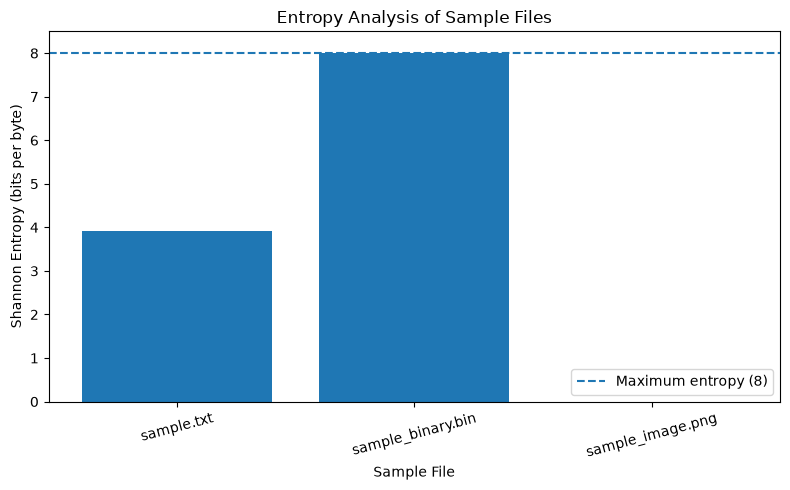

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(entropy_df["filename"], entropy_df["entropy"])
plt.axhline(y=8, linestyle="--", label="Maximum entropy (8)")
plt.ylabel("Shannon Entropy (bits per byte)")
plt.xlabel("Sample File")
plt.title("Entropy Analysis of Sample Files")
plt.ylim(0, 8.5)
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [25]:
def classify_entropy(entropy):
    if entropy >= 7:
        return "High Entropy - Possible Encryption"
    elif entropy >= 5:
        return "Medium Entropy - Needs Investigation"
    else:
        return "Low Entropy"


entropy_df["entropy_result"] = entropy_df["entropy"].apply(
    classify_entropy
)

display(entropy_df)

,filename,size_bytes,entropy,entropy_result
0,sample.txt,4000,3.920951,Low Entropy
1,sample_binary.bin,25600,8.000000,High Entropy - Possible Encryption
2,sample_image.png,0,0.000000,Low Entropy


In [10]:
output_path = output_folder / "entropy_results.csv"

entropy_df.to_csv(output_path, index=False)

print("Updated entropy results saved to:", output_path)

Updated entropy results saved to: ..\dataset\processed\entropy_results.csv


In [26]:
from pathlib import Path

print("Model exists:", Path("../models/random_forest_baseline.joblib").exists())
print("Entropy results exist:", Path("../dataset/processed/entropy_results.csv").exists())
print("Feature importance exists:", Path("../dataset/processed/top20_feature_importance.csv").exists())

Model exists: True
Entropy results exist: True
Feature importance exists: True


In [27]:
import joblib
from pathlib import Path
import pandas as pd

# Load the saved machine-learning model
model = joblib.load("../models/random_forest_baseline.joblib")

# Load the saved entropy results
entropy_results = pd.read_csv(
    "../dataset/processed/entropy_results.csv"
)

display(entropy_results)
print("Random Forest model loaded successfully!")

,filename,size_bytes,entropy
0,sample.txt,4000,3.920951
1,sample_binary.bin,25600,8.000000
2,sample_image.png,0,0.000000


Random Forest model loaded successfully!


In [28]:
# Load the MLRan test dataset
X_test = pd.read_csv("../dataset/raw/MLRan_X_test_RFE.csv")

# Separate the actual labels
y_test = X_test["sample_type"]

# Keep only the 483 model features
X_test_features = X_test.drop(
    columns=["sample_id", "sample_type", "family_label", "type_label"]
)

# Predict using the saved Random Forest model
y_pred = model.predict(X_test_features)

# Display the prediction for the first test sample
print("Actual class:", y_test.iloc[0])
print("Predicted class:", y_pred[0])

Actual class: 1
Predicted class: 1


In [29]:
# Create a small demonstration table
combined_results = entropy_results.copy()

# Add the first test sample's ML prediction for reference
combined_results["ml_test_actual_class"] = int(y_test.iloc[0])
combined_results["ml_test_predicted_class"] = int(y_pred[0])

display(combined_results)

,filename,size_bytes,entropy,ml_test_actual_class,ml_test_predicted_class
0,sample.txt,4000,3.920951,1,1
1,sample_binary.bin,25600,8.000000,1,1
2,sample_image.png,0,0.000000,1,1


In [30]:
output_path = Path("../dataset/processed/combined_demo_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

combined_results.to_csv(output_path, index=False)

print("Combined demonstration results saved to:", output_path)

Combined demonstration results saved to: ..\dataset\processed\combined_demo_results.csv
